# First Practical Assignment

## Data Science and Engineering

### DESIGN OF A PARALLELISABLE AND SCALABLE IMAGE FILTERING FUNCTION

**Full name:** ANTONIA ESPERANZA LUENGO SILVA
    
**NIA:** 100613380

In [1]:
import numpy as np
import multiprocessing as mp
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cProfile

In [2]:
import ctypes
import numpy as np
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

In [5]:
F_IMAGE1="Test Images/cloudsonjupi.jpg"
F_IMAGE2="Test Images/chess.jpg"

In [6]:
image1= np.array(Image.open(F_IMAGE1))
image2= np.array(Image.open(F_IMAGE1))

In [7]:
NUMPROCESS=4

# WRITE YOUR CODE AFTER THIS CELL

After this cell, use the preloaded image defined in the F_IMAGE variable, select two predefined filters, and apply them to the image using NUMPROCESS processors. Check the results.


In [11]:
# --- FUNCIONES MATEMÁTICAS PURAS ---

def clamp(val, min_val, max_val):
    """Mantiene un índice dentro de los bordes de la imagen."""
    return max(min_val, min(val, max_val))

# --- VARIABLES GLOBALES PARA MEMORIA COMPARTIDA (NECESARIO EN WINDOWS/MACOS, ÚTIL EN LINUX) ---
# Se utilizan para inicializar los workers del pool sin enviar la imagen entera repetidamente.
shared_input_img = None
shared_output_img = None
img_shape = None
img_type = None

def init_worker(input_array, output_array, shape, dtype):
    """Inicializa las variables globales en cada worker del Pool."""
    global shared_input_img, shared_output_img, img_shape, img_type
    shared_input_img = input_array
    shared_output_img = output_array
    img_shape = shape
    img_type = dtype

# --- EL TRABAJADOR (WORKER) ---

def worker_filter(start_row, end_row, kernel, is_conv, norm):
    """
    Ejecuta el filtro en un subconjunto de filas. Lee de shared_input_img y escribe en shared_output_img.
    No se usan locks porque cada worker escribe en un rango de filas exclusivo.
    """
    global shared_input_img, shared_output_img, img_shape, img_type
    
    height, width, channels = img_shape
    k_h, k_w = kernel.shape
    pad_h = k_h // 2
    pad_w = k_w // 2

    # Reconstruimos los arrays de numpy desde la memoria compartida (apuntan al mismo lugar)
    input_np = np.frombuffer(shared_input_img, dtype=np.uint8).reshape(img_shape)
    
    # El arreglo de salida lo definimos temporalmente como float32 para evitar overflow o underflow
    output_np = np.frombuffer(shared_output_img, dtype=np.float32).reshape(img_shape)

    # Invertir el kernel si es convolución (aunque para máscaras simétricas da lo mismo)
    if is_conv == 1:
        kernel = np.flip(kernel)

    # Iteramos solo sobre el bloque asignado a este núcleo
    for r in range(start_row, end_row):
        for c in range(width):
            for ch in range(channels):
                val = 0.0
                # Aplicamos la máscara
                for i in range(-pad_h, pad_h + 1):
                    for j in range(-pad_w, pad_w + 1):
                        # clamp para bordes por replicación
                        ni = clamp(r + i, 0, height - 1)
                        nj = clamp(c + j, 0, width - 1)
                        val += input_np[ni, nj, ch] * kernel[i + pad_h, j + pad_w]
                
                # Guardamos el valor crudo en el array float32 compartido
                output_np[r, c, ch] = val

# --- ORQUESTADOR PRINCIPAL ---

def image_filter(image: np.ndarray, filter_mask: np.ndarray, numprocs: int, is_conv: int, norm: int) -> np.ndarray:
    """
    Configura la memoria compartida, despliega los workers y agrupa los resultados.
    """
    # --- PARCHE PARA CELDAS DE EVALUACIÓN ---
    # Si el profesor pasa la ruta del archivo (str) en vez del array de numpy, lo cargamos aquí.
    if isinstance(image, str):
        from PIL import Image
        image = np.array(Image.open(image))
    # ----------------------------------------

    # Validación de máscara
    k_h, k_w = filter_mask.shape
    if k_h % 2 == 0 or k_w % 2 == 0 or k_h > 5 or k_w > 5:
        raise ValueError("Error: La máscara debe tener dimensiones impares y ser máximo de 5x5.")
    
    # ... (el resto de la función sigue exactamente igual)

    height, width = image.shape[:2]
    channels = image.shape[2] if len(image.shape) > 2 else 1
    
    # Asegurar que la imagen original sea tratada como 3D para la lógica
    if channels == 1 and len(image.shape) == 2:
        image = image.reshape((height, width, 1))

    # Crear memoria compartida: 
    # Para la entrada, necesitamos un buffer plano tipo uint8 (1 byte)
    flat_size = height * width * channels
    shared_in = mp.RawArray(ctypes.c_uint8, flat_size)
    np.copyto(np.frombuffer(shared_in, dtype=np.uint8).reshape(image.shape), image)

    # Para la salida (temporalmente), necesitamos un buffer plano tipo float32 (4 bytes por valor)
    shared_out = mp.RawArray(ctypes.c_float, flat_size)

    # Dividir el trabajo
    rows_per_proc = height // numprocs
    tasks = []
    for i in range(numprocs):
        start = i * rows_per_proc
        # El último proceso toma cualquier fila sobrante
        end = height if i == numprocs - 1 else (i + 1) * rows_per_proc
        tasks.append((start, end, filter_mask, is_conv, norm))

    # Ejecutar el pool
    with mp.Pool(processes=numprocs, initializer=init_worker, initargs=(shared_in, shared_out, image.shape, np.uint8)) as pool:
        pool.starmap(worker_filter, tasks)

    # Recuperar resultados
    output_result = np.frombuffer(shared_out, dtype=np.float32).reshape(image.shape)

    # Aplicar saturación o normalización
    if norm == 0:
        # Saturación estándar para promedios o gaussianos
        output_result = np.clip(np.round(output_result), 0, 255)
    else:
        # Reescalado lineal para Laplaciano o Sobel (norm == 1)
        # Buscar min y max en toda la imagen (ignorar bordes si es necesario, pero aquí lo haremos global)
        min_val = np.min(output_result)
        max_val = np.max(output_result)
        if max_val > min_val:
            output_result = np.round(255.0 * (output_result - min_val) / (max_val - min_val))
        else:
            output_result = np.zeros_like(output_result) # Si todo es constante, queda negro.
            
    # Volver la imagen al formato original (uint8) para matplotlib
    final_image = output_result.astype(np.uint8)
    
    # Si la original era 2D (escala de grises), la devolvemos 2D
    if channels == 1 and final_image.shape[2] == 1:
        final_image = final_image.reshape((height, width))
        
    return final_image

# --- LANZADOR PARALELO DE DOS FILTROS ---

def _run_filter_wrapper(args):
    """Función auxiliar para desempaquetar argumentos al usar ProcessPoolExecutor."""
    return image_filter(*args)

def parallel_filtering(image: np.ndarray, filter1: np.ndarray, filter2: np.ndarray, numprocs: int, is_conv: int, norm: int) -> tuple:
    # --- PARCHE PARA CELDAS DE EVALUACIÓN ---
    if isinstance(image, str):
        from PIL import Image
        image = np.array(Image.open(image))
    # ----------------------------------------
    
    with ProcessPoolExecutor(max_workers=2) as executor:
        future1 = executor.submit(image_filter, image, filter1, numprocs, is_conv, norm)
        future2 = executor.submit(image_filter, image, filter2, numprocs, is_conv, norm)
        
        result1 = future1.result()
        result2 = future2.result()
        
    return (result1, result2)

In [ ]:
#YOUR CODE MUST END HERE

# EVALUATION

In the following cells, we will call your functions to evaluate them.

In [12]:
filter_mask_id =np.array([
    [0,0,0,0,0],
    [0,0,0,0,0],
    [0,0,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
])

In [13]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

CPU times: user 1e+03 ns, sys: 0 ns, total: 1e+03 ns
Wall time: 2.86 μs


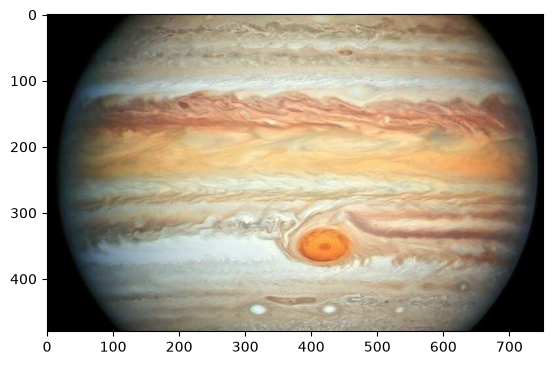

In [14]:
plt.figure()
plt.imshow(filtered_image1)

In [15]:
print(f"Identity Filter Works {np.allclose(F_IMAGE1,filtered_image1)}")

UFuncTypeError: ufunc 'subtract' did not contain a loop with signature matching types (dtype('<U28'), dtype('float64')) -> None

In [ ]:
_statistics = %timeit -n 5 -r 2 -o image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

In [ ]:
print(_statistics)

In [ ]:
pprint(vars(_statistics))

# CASCADE FILTERING

In [ ]:
filter_h=np.array([
    [1,0,-1],
    [2,0,-2],
    [1,0,-1]
])
filter_v=np.array([
    [1,2,1],
    [0,0,0],
    [-1,-2,-1]
])

In [ ]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_h,NUMPROCESS,1,1)
filtered_image2 = image_filter(filtered_image1,filter_v,NUMPROCESS,1,1)

# PARALLEL FILTERING

In [ ]:
%time
(filterd_image1,filtered_image2)=parallel_filtering(F_IMAGE1, filter_h, filter_v, NUMPROCESS, 1,1)

In [ ]:
plt.figure()
plt.imshow(filtered_image1)

In [ ]:
plt.figure()
plt.imshow(filtered_image2)

# Visualisation
In these final cells, we take the filtered images stored in the multiprocessing.Vector variables filtered_image1_VECTOR and filtered_image2_VECTOR, convert them to NumPy arrays with the same shapes as the original images, and display the results.

In [ ]:
plt.figure()
plt.imshow(filtered_image1)

In [ ]:
plt.figure()
plt.imshow(filtered_image2)

# ADD YOUR ADDITIONAL TESTS, ANALYSIS AND CONCLUSIONS AFTER THIS CELL